# Setup
run once at the start

In [3]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import torch
from torch.utils.data import DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt

from models.autoencoder import AutoEncoder
from scripts.engine import train_model
from datasets.deer_dataset import DeerDataset

In [ ]:
def run_model(size,
              loss_fn,
              optimizer,
              lr=1e-3,
              epochs=3):
        model = AutoEncoder(size)
        train_dataset = DeerDataset("../data/deer-iyhon", split="train", image_size=(size, size))
        train_dataloader = DataLoader(train_dataset,
                                batch_size=32,
                                shuffle=True)
        optimizer = optimizer(model.parameters(), lr=lr)
        model, history = train_model(model=model,
                dataloader=train_dataloader,
                optimizer=optimizer,
                loss_fn=loss_fn,
                epochs=3
                )

        plt.plot(history)
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.show()

        return model

def save_model(model, file_name):
        MODEL_DIR = PROJECT_ROOT / "models" / "pt"
        torch.save(
        model.state_dict(),
        MODEL_DIR / file_name)
    

# 128 avec MSE

In [ ]:
loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.Adam
model = run_model(size=128,
          loss_fn=loss_fn,
          optimizer=optimizer)

In [ ]:
save_model(model, "autoencoder128MSE.pt")

NameError: name 'model' is not defined

# Trying 512 px for image

In [ ]:
loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.Adam
model = run_model(size=256,
          loss_fn=loss_fn,
          optimizer=optimizer)

In [ ]:
save_model(model, "autoencoder512MSE.pt")

# Trying 256 with L1Loss

In [ ]:
loss_fn = torch.nn.L1Loss()
optimizer = torch.optim.Adam
model = run_model(size=256,
          loss_fn=loss_fn,
          optimizer=optimizer)

In [ ]:
save_model(model, "autoencoder256L1.pt")

# Trying model with 128 and BCE

the model activation layer is sigmoid so it should have better results if I use Binary Cross Entropy as the loss function.

Epoch 1/3: 100%|██████████| 96/96 [01:02<00:00,  1.54it/s, loss=0.5277]


Epoch 1 - Loss: 0.6261


Epoch 2/3: 100%|██████████| 96/96 [01:07<00:00,  1.43it/s, loss=0.5231]


Epoch 2 - Loss: 0.5519


Epoch 3/3: 100%|██████████| 96/96 [01:14<00:00,  1.28it/s, loss=0.5468]


Epoch 3 - Loss: 0.5449


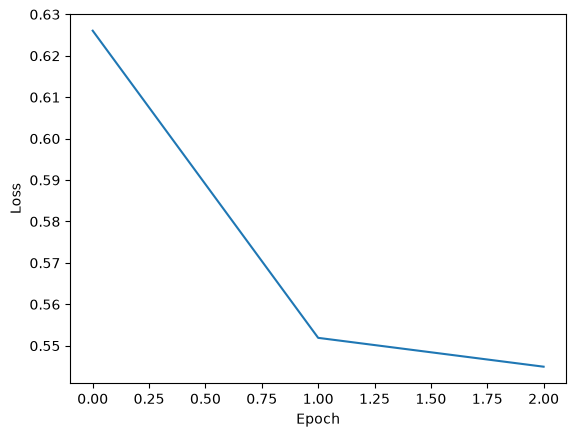

In [ ]:
loss_fn = torch.nn.BCELoss()
optimizer = torch.optim.Adam
model_256_BCE = run_model(size=256,
          loss_fn=loss_fn,
          optimizer=optimizer)

In [25]:
save_model(model_256_BCE, "autoencoder256BCE.pt")

In [30]:
!PYTHONPATH=.. python3 ../scripts/run_autoencoder.py ../data/deer-iyhon/valid/images/0c658a40338b7a50_jpg.rf.dfd7220079ad2fd3e37590d00706e4e3.jpg ../models/pt/autoencoder128BCE.pt 128